<a href="https://colab.research.google.com/github/dalkhaseeb-D/at-risk-student-prediction/blob/main/OULAD_New_Approach_Corrected.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from pathlib import Path
import subprocess

PROJECT_DIR = Path("/content/oulad_baseline_review")

if not PROJECT_DIR.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/dalkhaseeb-D/at-risk-student-prediction.git",
            str(PROJECT_DIR),
        ],
        check=True,
    )

commit = subprocess.check_output(
    ["git", "-C", str(PROJECT_DIR), "rev-parse", "HEAD"],
    text=True,
).strip()

print("GitHub version:", commit)
print("\nPython files:")
for path in sorted(PROJECT_DIR.rglob("*.py")):
    if ".git" not in path.parts:
        print(path.relative_to(PROJECT_DIR))

print("\nStep 1 completed.")

GitHub version: 9ce9278542c89ec878d2532eb7550e1aa39719be

Python files:
make_figures.py
run_experiment.py

Step 1 completed.


In [ ]:
import sys
import subprocess

requirements = PROJECT_DIR / "requirements.txt"

print("Installing project libraries...", flush=True)

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "-r", str(requirements)
    ],
    check=True
)

print("\nStep 2 completed: libraries installed.")

Installing project libraries...

Step 2 completed: libraries installed.


In [ ]:
import sys
import importlib
import json

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

original = importlib.import_module("run_experiment")

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "student_grouped_results"
FIGURES_DIR = PROJECT_DIR / "student_grouped_figures"

for folder in [DATA_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("1. Downloading OULAD data...", flush=True)
original.download_oulad(DATA_DIR)

print("\n2. Auditing the data...", flush=True)
tables = original.audit(DATA_DIR, RESULTS_DIR)

print("\n3. Building the original day-28 dataset...", flush=True)
model_data = original.build_dataset(
    tables, DATA_DIR, RESULTS_DIR
)

# At prediction time, the registration must already have started.
late_registration = model_data["date_registration"].gt(28)

print(
    "\nRegistrations starting after day 28:",
    int(late_registration.sum())
)

model_data = (
    model_data.loc[~late_registration]
    .reset_index(drop=True)
)

print("\nCorrected registrations:", len(model_data))
print("Unique students:", model_data["id_student"].nunique())
print(
    "At-risk percentage:",
    round(model_data["target_at_risk"].mean() * 100, 2)
)

model_data.to_csv(
    RESULTS_DIR / "day28_model_data.csv",
    index=False
)

print("\nStep 3 completed: data ready; no models trained.")

1. Downloading OULAD data...
[data] downloading OULAD from https://archive.ics.uci.edu/static/public/349/open%2Buniversity%2Blearning%2Banalytics%2Bdataset.zip

2. Auditing the data...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                   File     Rows  Columns  Duplicate_Rows  NaN_naive_audit  Missing_as_?
            courses.csv       22        3               0                0             0
        assessments.csv      206        6               0                0            11
        studentInfo.csv    32593       12               0                0          1111
studentRegistration.csv    32593        5               0                0         22566
  studentAssessment.csv   173912        5               0                0           173
                vle.csv     6364        6               0                0         10486
         studentVle.csv 10655280        6          787170                0             0
               File              Column  Missing
        assessments                date       11
        studentInfo            imd_band     1111
studentRegistration   date_registration       45
studentRegistration date_unregistration    22521
  studentAssessment               score    

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

{
  "registrations": 32593,
  "withdrew_before_day28_excluded": 5055,
  "eligible_at_day28": 27538,
  "at_risk": 12153,
  "at_risk_pct": 44.13,
  "no_vle_activity_wk1_4": 1246,
  "unique_students": 24839,
  "students_with_multiple_registrations": 2578,
  "final_result_counts": {
    "Pass": 12361,
    "Fail": 7044,
    "Withdrawn": 5109,
    "Distinction": 3024
  }
}

Registrations starting after day 28: 16

Corrected registrations: 27522
Unique students: 24832
At-risk percentage: 44.12

Step 3 completed: data ready; no models trained.


In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

categorical_features = original.CATEGORICAL
numeric_features = original.PROFILE_NUMERIC + original.ENGAGEMENT

X = model_data[categorical_features + numeric_features].copy()
y = model_data["target_at_risk"].copy()
groups = model_data["id_student"].copy()

assert groups.notna().all(), "Some student IDs are missing."

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Use the first fold, fixed before training or viewing performance.
train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_students = set(groups.iloc[train_idx])
test_students = set(groups.iloc[test_idx])
overlap = train_students & test_students

assert len(overlap) == 0, "Student overlap detected!"

split_summary = pd.DataFrame([
    {
        "Partition": "Train",
        "Registrations": len(train_idx),
        "Unique students": len(train_students),
        "At-risk %": round(y_train.mean() * 100, 2)
    },
    {
        "Partition": "Test",
        "Registrations": len(test_idx),
        "Unique students": len(test_students),
        "At-risk %": round(y_test.mean() * 100, 2)
    }
])

display(split_summary)
print("Students shared between train and test:", len(overlap))

assignments = model_data[original.KEYS].copy()
assignments["partition"] = ""
assignments.loc[X_train.index, "partition"] = "train"
assignments.loc[X_test.index, "partition"] = "test"

assignments.to_csv(
    RESULTS_DIR / "student_split_assignments.csv",
    index=False
)

split_summary.to_csv(
    RESULTS_DIR / "student_split_summary.csv",
    index=False
)

print("\nStep 4 completed: student-separated split saved.")

,Partition,Registrations,Unique students,At-risk %
0,Train,22017,19865,44.12
1,Test,5505,4967,44.12


Students shared between train and test: 0

Step 4 completed: student-separated split saved.


In [ ]:
import numpy as np
import pandas as pd

print("Training the original baseline models...", flush=True)

model_results, fitted_models = original.fit_and_score(
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    categorical=categorical_features,
    numeric=numeric_features
)

model_results = (
    model_results
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

model_results.to_csv(
    RESULTS_DIR / "04_model_comparison.csv",
    index=False
)

# Same fixed ensemble as the original project.
ensemble_names = [
    "Logistic Regression",
    "Random Forest",
    "Gradient Boosting"
]

ensemble_probabilities = np.mean(
    [
        fitted_models[name].predict_proba(X_test)[:, 1]
        for name in ensemble_names
    ],
    axis=0
)

ensemble_predictions = (
    ensemble_probabilities >= 0.5
).astype(int)

ensemble_result = pd.DataFrame([{
    "Model": "Soft Voting Ensemble (LR+RF+GB)",
    **original.scores(
        y_test,
        ensemble_predictions,
        ensemble_probabilities
    )
}])

ensemble_result.to_csv(
    RESULTS_DIR / "04_ensemble.csv",
    index=False
)

print("\nIndividual models:")
display(model_results.round(3))

print("\nFixed soft-voting ensemble:")
display(ensemble_result.round(3))

# Save test predictions for reproducibility.
test_predictions = model_data.loc[
    X_test.index,
    original.KEYS + ["target_at_risk"]
].copy()

for name, pipeline in fitted_models.items():
    test_predictions[f"{name}_probability"] = (
        pipeline.predict_proba(X_test)[:, 1]
    )

test_predictions["ensemble_probability"] = ensemble_probabilities

test_predictions.to_csv(
    RESULTS_DIR / "04_test_predictions.csv",
    index=False
)

print("\nStep 5 completed: models evaluated and results saved.")

Training the original baseline models...

Individual models:


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Train time (s),Parameters / nodes,Size (KB)
0,Logistic Regression,0.679,0.678,0.628,0.671,0.648,0.744,0.383,53,1.108
1,Gradient Boosting,0.683,0.678,0.640,0.641,0.641,0.747,1.073,5734,337.850
2,Random Forest,0.680,0.674,0.642,0.621,0.631,0.740,2.407,242534,19011.212
3,Decision Tree,0.665,0.655,0.637,0.563,0.597,0.712,0.182,319,26.053
4,Dummy Baseline,0.559,0.500,0.000,0.000,0.000,0.500,0.105,2,0.466



Fixed soft-voting ensemble:


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC
0,Soft Voting Ensemble (LR+RF+GB),0.683,0.679,0.638,0.648,0.643,0.749



Step 5 completed: models evaluated and results saved.


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

train_groups = model_data.loc[
    X_train.index, "id_student"
]

grouped_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Fix and audit all folds before training.
cv_splits = list(
    grouped_cv.split(
        X_train,
        y_train,
        groups=train_groups
    )
)

fold_audit = []

for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
    fit_students = set(train_groups.iloc[fit_idx])
    val_students = set(train_groups.iloc[val_idx])

    shared = len(fit_students & val_students)
    assert shared == 0

    fold_audit.append({
        "Fold": fold,
        "Training registrations": len(fit_idx),
        "Validation registrations": len(val_idx),
        "Student overlap": shared
    })

fold_audit = pd.DataFrame(fold_audit)
display(fold_audit)

fold_audit.to_csv(
    RESULTS_DIR / "06_grouped_cv_fold_audit.csv",
    index=False
)

scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_rows = []

for name, model in original.make_models().items():
    if name == "Dummy Baseline":
        continue

    print("Grouped CV:", name, flush=True)

    pipeline = Pipeline([
        (
            "pre",
            original.make_preprocessor(
                categorical_features,
                numeric_features
            )
        ),
        ("model", model)
    ])

    result = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1
    )

    for metric in scoring:
        cv_rows.append({
            "Model": name,
            "Metric": metric,
            "Train mean": result[f"train_{metric}"].mean(),
            "Validation mean": result[f"test_{metric}"].mean(),
            "Validation SD": result[f"test_{metric}"].std(ddof=1)
        })

cv_summary = pd.DataFrame(cv_rows)

cv_summary.to_csv(
    RESULTS_DIR / "06_grouped_cross_validation.csv",
    index=False
)

display(cv_summary.round(3))

print("\nStep 6 completed: grouped CV on training data only.")

,Fold,Training registrations,Validation registrations,Student overlap
0,1,17614,4403,0
1,2,17614,4403,0
2,3,17614,4403,0
3,4,17613,4404,0
4,5,17613,4404,0


Grouped CV: Logistic Regression
Grouped CV: Decision Tree
Grouped CV: Random Forest
Grouped CV: Gradient Boosting


,Model,Metric,Train mean,Validation mean,Validation SD
0,Logistic Regression,balanced_accuracy,0.680,0.678,0.008
1,Logistic Regression,precision,0.628,0.626,0.010
2,Logistic Regression,recall,0.676,0.674,0.011
3,Logistic Regression,f1,0.651,0.649,0.009
4,Logistic Regression,roc_auc,0.746,0.742,0.008
5,Decision Tree,balanced_accuracy,0.682,0.649,0.007
6,Decision Tree,precision,0.644,0.608,0.014
7,Decision Tree,recall,0.648,0.610,0.025
8,Decision Tree,f1,0.645,0.608,0.009
9,Decision Tree,roc_auc,0.753,0.708,0.009



Step 6 completed: grouped CV on training data only.


In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
import pandas as pd

feature_sets = {
    "Profile only": (
        original.CATEGORICAL,
        original.PROFILE_NUMERIC
    ),
    "Engagement only": (
        [],
        original.ENGAGEMENT
    ),
    "Profile + engagement": (
        categorical_features,
        numeric_features
    )
}

ablation_rows = []

for feature_set, (cats, nums) in feature_sets.items():
    for name, model in original.make_models().items():

        if name == "Dummy Baseline":
            continue

        print(feature_set, "|", name, flush=True)

        pipeline = Pipeline([
            (
                "pre",
                original.make_preprocessor(cats, nums)
            ),
            ("model", model)
        ])

        result = cross_validate(
            pipeline,
            X_train[cats + nums],
            y_train,
            cv=cv_splits,
            scoring={"f1": "f1", "roc_auc": "roc_auc"},
            n_jobs=1
        )

        ablation_rows.append({
            "Feature set": feature_set,
            "Model": name,
            "F1 mean": result["test_f1"].mean(),
            "F1 SD": result["test_f1"].std(ddof=1),
            "AUC mean": result["test_roc_auc"].mean(),
            "AUC SD": result["test_roc_auc"].std(ddof=1)
        })

ablation_results = pd.DataFrame(ablation_rows)

ablation_results.to_csv(
    RESULTS_DIR / "07_ablation_grouped_cv.csv",
    index=False
)

display(ablation_results.round(3))

print("\nStep 7 completed: feature ablation saved.")

Profile only | Logistic Regression
Profile only | Decision Tree
Profile only | Random Forest
Profile only | Gradient Boosting
Engagement only | Logistic Regression
Engagement only | Decision Tree
Engagement only | Random Forest
Engagement only | Gradient Boosting
Profile + engagement | Logistic Regression
Profile + engagement | Decision Tree
Profile + engagement | Random Forest
Profile + engagement | Gradient Boosting


,Feature set,Model,F1 mean,F1 SD,AUC mean,AUC SD
0,Profile only,Logistic Regression,0.579,0.008,0.654,0.008
1,Profile only,Decision Tree,0.560,0.006,0.628,0.007
2,Profile only,Random Forest,0.570,0.006,0.652,0.007
3,Profile only,Gradient Boosting,0.576,0.007,0.651,0.005
4,Engagement only,Logistic Regression,0.609,0.007,0.671,0.007
5,Engagement only,Decision Tree,0.594,0.002,0.658,0.007
6,Engagement only,Random Forest,0.582,0.003,0.663,0.007
7,Engagement only,Gradient Boosting,0.594,0.007,0.668,0.008
8,Profile + engagement,Logistic Regression,0.649,0.009,0.742,0.008
9,Profile + engagement,Decision Tree,0.608,0.009,0.708,0.009



Step 7 completed: feature ablation saved.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Held-out test results
comparison = pd.concat(
    [
        model_results[
            ["Model", "Precision", "Recall", "F1", "ROC-AUC"]
        ],
        ensemble_result[
            ["Model", "Precision", "Recall", "F1", "ROC-AUC"]
        ]
    ],
    ignore_index=True
)

ax = comparison.set_index("Model").plot.bar(
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Baseline Models: Student-Separated Test Set")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "01_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 2. Feature-group comparison using grouped CV
feature_order = [
    "Profile only",
    "Engagement only",
    "Profile + engagement"
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, sd_column, title in [
    (axes[0], "F1 mean", "F1 SD", "At-Risk F1"),
    (axes[1], "AUC mean", "AUC SD", "ROC-AUC")
]:
    means = ablation_results.pivot(
        index="Feature set",
        columns="Model",
        values=metric
    ).reindex(feature_order)

    deviations = ablation_results.pivot(
        index="Feature set",
        columns="Model",
        values=sd_column
    ).reindex(
        index=feature_order,
        columns=means.columns
    )

    means.plot.bar(
        ax=ax,
        yerr=deviations,
        capsize=3,
        width=0.8
    )

    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Feature Ablation: Five-Fold Student-Grouped CV\n"
    "Training partition only; error bars show fold SD"
)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "02_feature_ablation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 3. Training vs validation AUC
auc_summary = (
    cv_summary.loc[cv_summary["Metric"] == "roc_auc"]
    .set_index("Model")
)

positions = np.arange(len(auc_summary))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    positions - width / 2,
    auc_summary["Train mean"],
    width,
    label="Training"
)

ax.bar(
    positions + width / 2,
    auc_summary["Validation mean"],
    width,
    yerr=auc_summary["Validation SD"],
    capsize=4,
    label="Grouped validation"
)

ax.set_xticks(positions)
ax.set_xticklabels(auc_summary.index, rotation=15)
ax.set_ylim(0, 1)
ax.set_ylabel("ROC-AUC")
ax.set_title("Training vs Student-Grouped Validation AUC")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "03_train_validation_auc.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Step 8 completed. Saved figures:")
for path in sorted(FIGURES_DIR.glob("*.png")):
    print(path.name)

Step 8 completed. Saved figures:
01_model_comparison.png
02_feature_ablation.png
03_train_validation_auc.png


In [ ]:
import json
import platform
import subprocess
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import sklearn
import pandas as pd
from google.colab import files

# Record the exact source version and current experiment.
metadata = {
    "source_repository":
        "https://github.com/dalkhaseeb-D/at-risk-student-prediction",
    "source_commit": subprocess.check_output(
        ["git", "-C", str(PROJECT_DIR), "rev-parse", "HEAD"],
        text=True
    ).strip(),
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "registrations": len(model_data),
    "unique_students": int(model_data["id_student"].nunique()),
    "at_risk_percentage": float(
        model_data["target_at_risk"].mean() * 100
    ),
    "features": list(X.columns),
    "train_registrations": len(X_train),
    "test_registrations": len(X_test),
    "student_overlap": len(overlap),
    "main_split": "First fold of shuffled StratifiedGroupKFold",
    "seed": 42,
    "cv": "5-fold student-grouped CV on training partition only",
    "classification_threshold": 0.5,
    "cohort_correction":
        "Exclude registrations starting after day 28; "
        "retain missing registration dates",
    "note":
        "02_dataset_summary.json describes the original cohort "
        "before the late-registration correction. "
        "This metadata describes the corrected run."
}

(RESULTS_DIR / "corrected_run_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

checkpoint = Path("/content/OULAD_Baseline_Grouped_Checkpoint.zip")

with ZipFile(checkpoint, "w", ZIP_DEFLATED) as archive:
    for folder, label in [
        (RESULTS_DIR, "results"),
        (FIGURES_DIR, "figures")
    ]:
        for path in folder.rglob("*"):
            if path.is_file():
                archive.write(
                    path,
                    Path(label) / path.relative_to(folder)
                )

    for name in [
        "run_experiment.py",
        "make_figures.py",
        "requirements.txt"
    ]:
        path = PROJECT_DIR / name
        if path.exists():
            archive.write(path, Path("original_source") / name)

print("Checkpoint created.")
files.download(str(checkpoint))

Checkpoint created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from google.colab import files
from pathlib import Path
from zipfile import ZipFile
import io
import pandas as pd

uploaded = files.upload()
zip_name = next(
    name for name in uploaded if name.lower().endswith(".zip")
)

ARWA_DIR = Path("/content/arwa_corrected")
ARWA_DIR.mkdir(parents=True, exist_ok=True)

with ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    for name in archive.namelist():
        parts = Path(name).parts

        # Extract source scripts only, without loading saved models.
        if len(parts) == 2 and name.endswith(".py"):
            (ARWA_DIR / Path(name).name).write_bytes(
                archive.read(name)
            )

        if name.endswith("/data/oulad_day28_features.csv"):
            (ARWA_DIR / "oulad_day28_features.csv").write_bytes(
                archive.read(name)
            )

arwa_data = pd.read_csv(
    ARWA_DIR / "oulad_day28_features.csv"
)

print("Registrations:", len(arwa_data))
print("Unique students:", arwa_data["id_student"].nunique())
print("At-risk %:", round(arwa_data["at_risk"].mean() * 100, 2))
print("Ready: Arwa's code and data loaded.")


Saving oulad_selected16_Code_with_Results.zip to oulad_selected16_Code_with_Results.zip
Registrations: 27522
Unique students: 24832
At-risk %: 44.12
Ready: Arwa's code and data loaded.


In [3]:
from google.colab import files
from zipfile import ZipFile
from sklearn.model_selection import StratifiedGroupKFold
import io
import numpy as np
import pandas as pd

checkpoint_upload = files.upload()
checkpoint_name = next(
    n for n in checkpoint_upload if n.lower().endswith(".zip")
)

with ZipFile(io.BytesIO(checkpoint_upload[checkpoint_name])) as z:
    split_file = next(
        n for n in z.namelist()
        if n.endswith("student_split_assignments.csv")
    )
    baseline_split = pd.read_csv(z.open(split_file))

KEYS = ["code_module", "code_presentation", "id_student"]

assert not arwa_data.duplicated(KEYS).any()
assert not baseline_split.duplicated(KEYS).any()

# Exact registration match, preserving Arwa's input order.
data16 = arwa_data.merge(
    baseline_split[KEYS + ["partition"]],
    on=KEYS,
    how="outer",
    validate="one_to_one",
    indicator=True
)

assert data16["_merge"].eq("both").all(), (
    "The two datasets contain different registrations."
)
data16 = data16.drop(columns="_merge").reset_index(drop=True)

train16_idx = np.flatnonzero(data16["partition"].eq("train"))
test16_idx = np.flatnonzero(data16["partition"].eq("test"))

assert len(train16_idx) == 22017
assert len(test16_idx) == 5505

train_ids = set(data16.iloc[train16_idx]["id_student"])
test_ids = set(data16.iloc[test16_idx]["id_student"])
assert not train_ids.intersection(test_ids)

# Validation comes ONLY from the training partition.
development16 = data16.iloc[train16_idx]

validation_splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

fit_local, val_local = next(
    validation_splitter.split(
        development16,
        development16["at_risk"],
        groups=development16["id_student"]
    )
)

fit16_idx = train16_idx[fit_local]
val16_idx = train16_idx[val_local]

fit_ids = set(data16.iloc[fit16_idx]["id_student"])
val_ids = set(data16.iloc[val16_idx]["id_student"])

assert not fit_ids.intersection(val_ids)
assert not (fit_ids | val_ids).intersection(test_ids)

ARWA_OUT = ARWA_DIR / "corrected_results"
ARWA_OUT.mkdir(parents=True, exist_ok=True)

assignments16 = data16[KEYS + ["partition"]].copy()
assignments16["development_partition"] = "test"
assignments16.loc[fit16_idx, "development_partition"] = "fit"
assignments16.loc[val16_idx, "development_partition"] = "validation"
assignments16.to_csv(
    ARWA_OUT / "verified_split_assignments.csv", index=False
)

print("Exact cohort match: PASS")
print("Baseline training registrations:", len(train16_idx))
print("Baseline test registrations:", len(test16_idx))
print("Fit:", len(fit16_idx), "| Validation:", len(val16_idx))
print("Student overlap across fit / validation / test: 0")
print("Ready for training.")

Saving OULAD_Baseline_Grouped_Checkpoint.zip to OULAD_Baseline_Grouped_Checkpoint.zip
Exact cohort match: PASS
Baseline training registrations: 22017
Baseline test registrations: 5505
Fit: 17620 | Validation: 4397
Student overlap across fit / validation / test: 0
Ready for training.


In [4]:
import sys
import subprocess
import importlib.util
import time
import numpy as np
import pandas as pd
import joblib

# Install only missing dependencies.
for package in ["xgboost", "torch", "shap", "seaborn"]:
    if importlib.util.find_spec(package) is None:
        print("Installing:", package, flush=True)
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", package
        ])

# Load Arwa's model definitions without running her old pipeline.
spec = importlib.util.spec_from_file_location(
    "arwa_models",
    ARWA_DIR / "run_all_oulad_experiments.py"
)
arwa = importlib.util.module_from_spec(spec)
spec.loader.exec_module(arwa)

X16 = data16[arwa.ALL_FEATURES].replace("?", np.nan)
y16 = data16["at_risk"].astype(int).to_numpy()

assert X16.shape[1] == 16

from sklearn.metrics import f1_score

results16 = []
threshold_search16 = []
predictions16 = data16.iloc[test16_idx][KEYS + ["at_risk"]].copy()
models16 = {}

for name, factory in [
    ("Logistic Regression", arwa.get_lr_model),
    ("XGBoost", arwa.get_xgb_model)
]:
    print(f"\nTraining {name} — validation stage...", flush=True)
    start = time.perf_counter()

    # Fit preprocessing ONLY on the fitting partition.
    prep_selection = arwa.build_preprocessor(arwa.ALL_FEATURES)
    X_fit = prep_selection.fit_transform(X16.iloc[fit16_idx])
    X_val = prep_selection.transform(X16.iloc[val16_idx])

    selection_model = factory()
    selection_model.fit(X_fit, y16[fit16_idx])
    val_prob = selection_model.predict_proba(X_val)[:, 1]

    # Predefined grid; select threshold using validation F1 only.
    grid = np.round(np.arange(0.25, 0.751, 0.05), 2)
    val_f1 = [
        f1_score(y16[val16_idx], val_prob >= t, zero_division=0)
        for t in grid
    ]
    best_threshold = float(grid[np.argmax(val_f1)])

    for threshold, score in zip(grid, val_f1):
        threshold_search16.append({
            "Model": name,
            "Threshold": threshold,
            "Validation_F1": score
        })

    print(
        f"{name}: threshold fixed at {best_threshold:.2f}. "
        "Refitting on all training data...",
        flush=True
    )

    # Refit using all 22,017 training registrations.
    prep_final = arwa.build_preprocessor(arwa.ALL_FEATURES)
    X_train_final = prep_final.fit_transform(X16.iloc[train16_idx])
    X_test_final = prep_final.transform(X16.iloc[test16_idx])

    model_final = factory()
    model_final.fit(X_train_final, y16[train16_idx])
    test_prob = model_final.predict_proba(X_test_final)[:, 1]

    for label, threshold in [
        ("Fixed 0.50", 0.50),
        ("Validation-selected", best_threshold)
    ]:
        metrics = arwa.compute_metrics(
            y16[test16_idx], test_prob, threshold=threshold
        )
        results16.append({
            "Model": name,
            "Threshold_rule": label,
            "Threshold": threshold,
            **metrics
        })

    predictions16[f"{name}_probability"] = test_prob
    models16[name] = (prep_final, model_final)

    joblib.dump(
        (prep_final, model_final, best_threshold),
        ARWA_OUT / f"{name.replace(' ', '_')}_pipeline.joblib"
    )

    print(
        f"{name} completed in {time.perf_counter() - start:.1f} seconds.",
        flush=True
    )

results16 = pd.DataFrame(results16)
results16.to_csv(ARWA_OUT / "main_comparison_16features.csv", index=False)

pd.DataFrame(threshold_search16).to_csv(
    ARWA_OUT / "validation_threshold_search.csv", index=False
)
predictions16.to_csv(
    ARWA_OUT / "test_predictions.csv", index=False
)

display(results16[[
    "Model", "Threshold_rule", "Threshold",
    "Precision", "Recall", "F1_Score", "ROC_AUC"
]].round(3))

print("LR and XGBoost completed. CNN is next.", flush=True)


Training Logistic Regression — validation stage...
Logistic Regression: threshold fixed at 0.35. Refitting on all training data...
Logistic Regression completed in 1.2 seconds.

Training XGBoost — validation stage...
XGBoost: threshold fixed at 0.35. Refitting on all training data...
XGBoost completed in 1.5 seconds.


,Model,Threshold_rule,Threshold,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,Fixed 0.50,0.50,0.686,0.657,0.671,0.778
1,Logistic Regression,Validation-selected,0.35,0.575,0.850,0.686,0.778
2,XGBoost,Fixed 0.50,0.50,0.722,0.587,0.648,0.781
3,XGBoost,Validation-selected,0.35,0.617,0.774,0.687,0.781


LR and XGBoost completed. CNN is next.


In [5]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import time
import numpy as np
import pandas as pd
import joblib

torch.set_num_threads(2)
device16 = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("CNN device:", device16, "| Epochs per stage: 25", flush=True)

def fit_cnn16(X_train, y_train, X_predict, stage):
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    model = arwa.Tabular1DCNN(X_train.shape[1]).to(device16)

    dataset = TensorDataset(
        torch.as_tensor(np.asarray(X_train), dtype=torch.float32).unsqueeze(1),
        torch.as_tensor(np.asarray(y_train), dtype=torch.float32)
    )
    loader = DataLoader(dataset, batch_size=256, shuffle=True)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=1e-3, weight_decay=1e-4
    )
    loss_function = torch.nn.BCEWithLogitsLoss()
    started = time.perf_counter()

    for epoch in range(1, 26):
        model.train()
        total_loss = 0.0

        for bx, by in loader:
            bx, by = bx.to(device16), by.to(device16)
            optimizer.zero_grad()
            loss = loss_function(model(bx), by)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(by)

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"{stage}: epoch {epoch}/25 | "
                f"loss {total_loss / len(dataset):.4f} | "
                f"{time.perf_counter() - started:.0f}s",
                flush=True
            )

    model.eval()
    probabilities = []

    with torch.no_grad():
        for start in range(0, len(X_predict), 1024):
            batch = torch.as_tensor(
                np.asarray(X_predict[start:start + 1024]),
                dtype=torch.float32
            ).unsqueeze(1).to(device16)

            probabilities.append(
                torch.sigmoid(model(batch)).cpu().numpy()
            )

    return model, np.concatenate(probabilities)

# Stage 1: choose threshold using validation only.
cnn_prep_selection = arwa.build_preprocessor(arwa.ALL_FEATURES)
cnn_X_fit = cnn_prep_selection.fit_transform(X16.iloc[fit16_idx])
cnn_X_val = cnn_prep_selection.transform(X16.iloc[val16_idx])

cnn_selection, cnn_val_prob = fit_cnn16(
    cnn_X_fit, y16[fit16_idx], cnn_X_val, "Validation training"
)

cnn_grid = np.round(np.arange(0.25, 0.751, 0.05), 2)
cnn_val_scores = [
    f1_score(y16[val16_idx], cnn_val_prob >= t, zero_division=0)
    for t in cnn_grid
]
cnn_threshold = float(cnn_grid[np.argmax(cnn_val_scores)])

print(
    f"\nCNN threshold fixed from validation: {cnn_threshold:.2f}",
    flush=True
)

# Stage 2: refit on all training registrations.
del cnn_selection
if torch.cuda.is_available():
    torch.cuda.empty_cache()

cnn_prep_final = arwa.build_preprocessor(arwa.ALL_FEATURES)
cnn_X_train = cnn_prep_final.fit_transform(X16.iloc[train16_idx])
cnn_X_test = cnn_prep_final.transform(X16.iloc[test16_idx])

cnn_final, cnn_test_prob = fit_cnn16(
    cnn_X_train, y16[train16_idx], cnn_X_test, "Final training"
)

cnn_rows = []
for rule, threshold in [
    ("Fixed 0.50", 0.50),
    ("Validation-selected", cnn_threshold)
]:
    cnn_rows.append({
        "Model": "1D-CNN (6 Layers)",
        "Threshold_rule": rule,
        "Threshold": threshold,
        **arwa.compute_metrics(
            y16[test16_idx], cnn_test_prob, threshold=threshold
        )
    })

results16 = pd.concat([
    results16[results16["Model"] != "1D-CNN (6 Layers)"],
    pd.DataFrame(cnn_rows)
], ignore_index=True)

results16.to_csv(
    ARWA_OUT / "main_comparison_16features.csv", index=False
)

predictions16["CNN_probability"] = cnn_test_prob
predictions16.to_csv(ARWA_OUT / "test_predictions.csv", index=False)

pd.DataFrame({
    "Threshold": cnn_grid,
    "Validation_F1": cnn_val_scores
}).to_csv(ARWA_OUT / "cnn_validation_threshold_search.csv", index=False)

joblib.dump(cnn_prep_final, ARWA_OUT / "cnn_preprocessor.joblib")
torch.save({
    "state_dict": {
        key: value.detach().cpu()
        for key, value in cnn_final.state_dict().items()
    },
    "num_features": cnn_X_train.shape[1],
    "threshold": cnn_threshold,
    "epochs": 25,
    "seed": 42
}, ARWA_OUT / "cnn_model.pt")

display(results16[[
    "Model", "Threshold_rule", "Threshold",
    "Precision", "Recall", "F1_Score", "ROC_AUC"
]].round(3))

print("All three models completed and results saved.", flush=True)

CNN device: cpu | Epochs per stage: 25
Validation training: epoch 1/25 | loss 0.5963 | 7s
Validation training: epoch 5/25 | loss 0.5589 | 37s
Validation training: epoch 10/25 | loss 0.5502 | 81s
Validation training: epoch 15/25 | loss 0.5457 | 118s
Validation training: epoch 20/25 | loss 0.5400 | 157s
Validation training: epoch 25/25 | loss 0.5355 | 196s

CNN threshold fixed from validation: 0.35
Final training: epoch 1/25 | loss 0.5877 | 10s
Final training: epoch 5/25 | loss 0.5568 | 46s
Final training: epoch 10/25 | loss 0.5491 | 96s
Final training: epoch 15/25 | loss 0.5460 | 143s
Final training: epoch 20/25 | loss 0.5437 | 193s
Final training: epoch 25/25 | loss 0.5390 | 238s


,Model,Threshold_rule,Threshold,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,Fixed 0.50,0.50,0.686,0.657,0.671,0.778
1,Logistic Regression,Validation-selected,0.35,0.575,0.850,0.686,0.778
2,XGBoost,Fixed 0.50,0.50,0.722,0.587,0.648,0.781
3,XGBoost,Validation-selected,0.35,0.617,0.774,0.687,0.781
4,1D-CNN (6 Layers),Fixed 0.50,0.50,0.777,0.469,0.585,0.772
5,1D-CNN (6 Layers),Validation-selected,0.35,0.695,0.626,0.658,0.772


All three models completed and results saved.


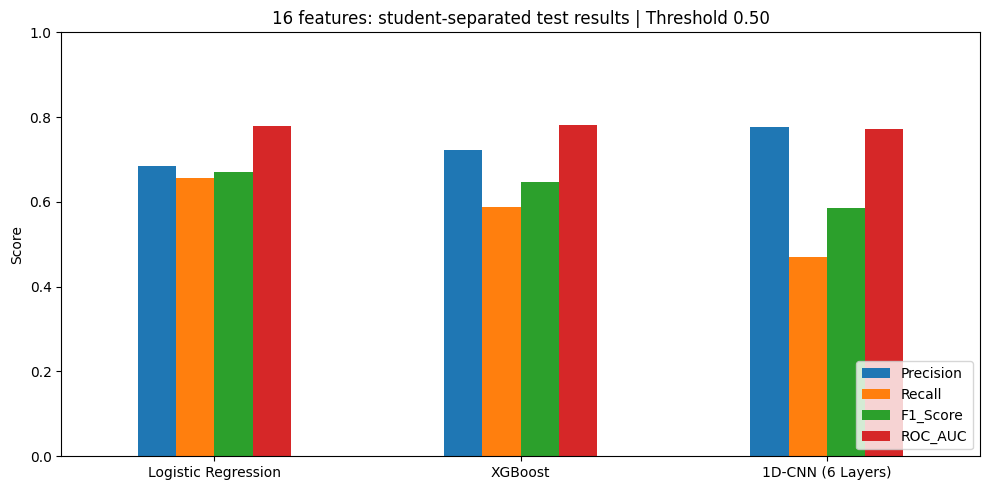

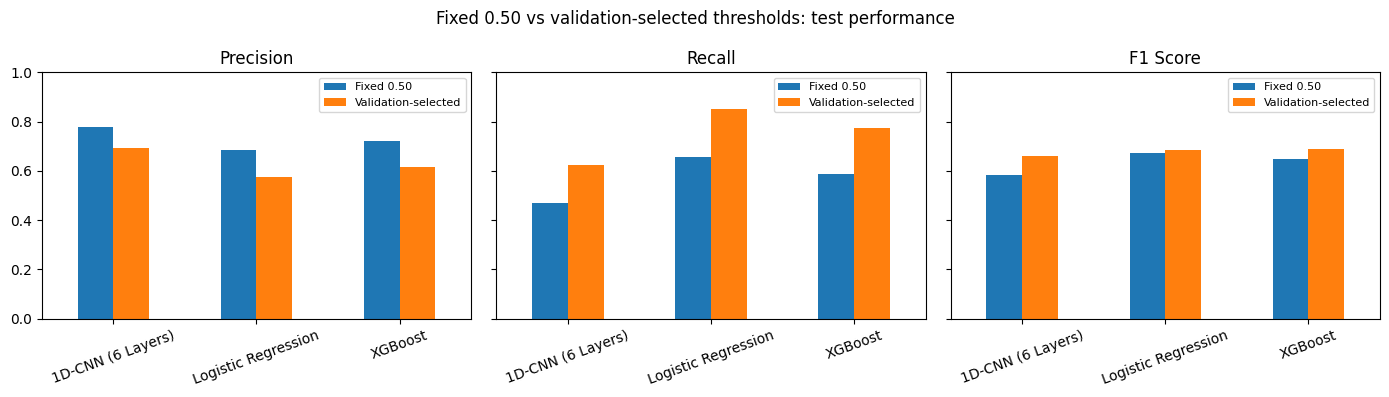

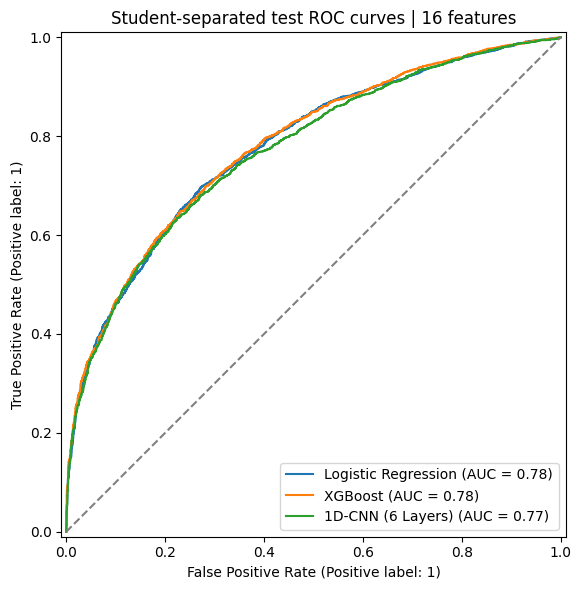

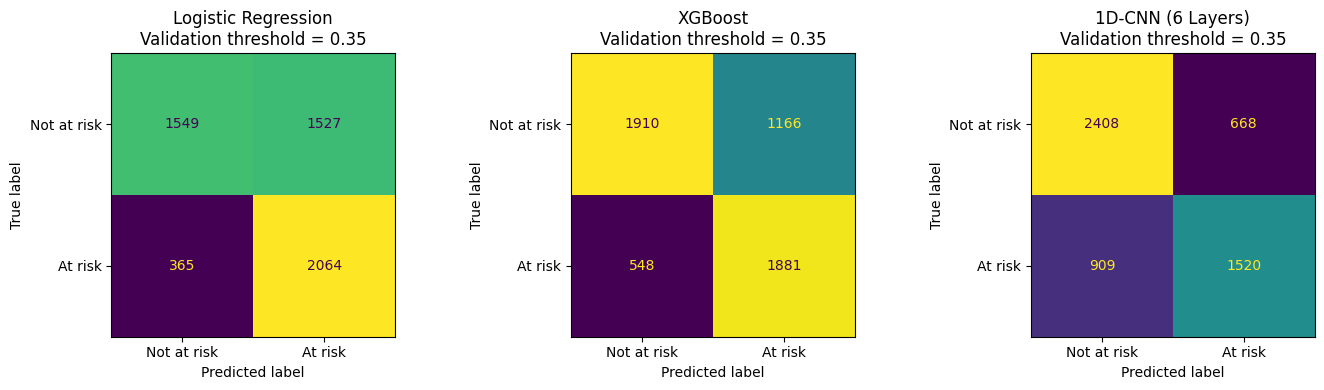

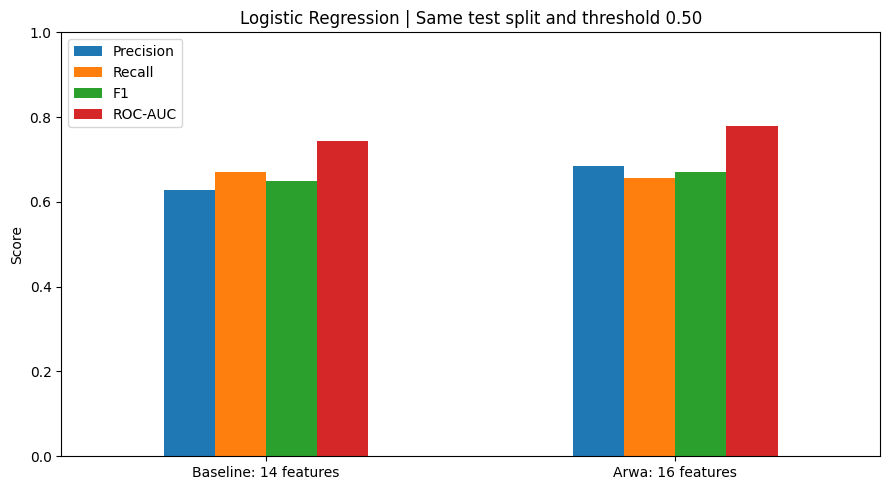

Figures and results saved. Downloading: OULAD_16Features_Corrected_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import json
import platform
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import (
    RocCurveDisplay, ConfusionMatrixDisplay
)
from google.colab import files

FIG16 = ARWA_OUT / "figures"
FIG16.mkdir(parents=True, exist_ok=True)

# 1. Compare all three models at the same fixed threshold.
fixed16 = results16[
    results16["Threshold_rule"].eq("Fixed 0.50")
].copy()

fig, ax = plt.subplots(figsize=(10, 5))
fixed16.set_index("Model")[[
    "Precision", "Recall", "F1_Score", "ROC_AUC"
]].plot.bar(ax=ax)
ax.set_ylim(0, 1)
ax.set_title("16 features: student-separated test results | Threshold 0.50")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG16 / "01_model_comparison.png", dpi=300)
plt.show()
plt.close(fig)

# 2. Show the precision / recall trade-off after threshold selection.
tuned16 = results16[
    results16["Threshold_rule"].eq("Validation-selected")
].copy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, metric in zip(axes, ["Precision", "Recall", "F1_Score"]):
    chart_data = results16.pivot(
        index="Model", columns="Threshold_rule", values=metric
    )
    chart_data.plot.bar(ax=ax)
    ax.set_title(metric.replace("_", " "))
    ax.set_ylim(0, 1)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(fontsize=8)
fig.suptitle("Fixed 0.50 vs validation-selected thresholds: test performance")
fig.tight_layout()
fig.savefig(FIG16 / "02_threshold_tradeoff.png", dpi=300)
plt.show()
plt.close(fig)

# 3. ROC curves use probabilities, so they do not depend on threshold.
probability_columns = {
    "Logistic Regression": "Logistic Regression_probability",
    "XGBoost": "XGBoost_probability",
    "1D-CNN (6 Layers)": "CNN_probability"
}
actual = predictions16["at_risk"].to_numpy()

fig, ax = plt.subplots(figsize=(7, 6))
for model_name, column in probability_columns.items():
    RocCurveDisplay.from_predictions(
        actual, predictions16[column].to_numpy(),
        name=model_name, ax=ax
    )
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_title("Student-separated test ROC curves | 16 features")
fig.tight_layout()
fig.savefig(FIG16 / "03_roc_curves.png", dpi=300)
plt.show()
plt.close(fig)

# 4. Confusion matrices at the validation-selected thresholds.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (model_name, column) in zip(
    axes, probability_columns.items()
):
    threshold = float(
        tuned16.loc[
            tuned16["Model"].eq(model_name), "Threshold"
        ].iloc[0]
    )
    ConfusionMatrixDisplay.from_predictions(
        actual,
        predictions16[column].to_numpy() >= threshold,
        display_labels=["Not at risk", "At risk"],
        colorbar=False,
        ax=ax
    )
    ax.set_title(f"{model_name}\nValidation threshold = {threshold:.2f}")
fig.tight_layout()
fig.savefig(FIG16 / "04_confusion_matrices.png", dpi=300)
plt.show()
plt.close(fig)

# 5. Compare LR feature sets at the SAME threshold.
with ZipFile(
    io.BytesIO(checkpoint_upload[checkpoint_name])
) as archive:
    baseline_name = next(
        name for name in archive.namelist()
        if name.endswith("04_model_comparison.csv")
    )
    baseline_results = pd.read_csv(archive.open(baseline_name))

baseline_lr = baseline_results.loc[
    baseline_results["Model"].eq("Logistic Regression")
].iloc[0]
new_lr = fixed16.loc[
    fixed16["Model"].eq("Logistic Regression")
].iloc[0]

feature_comparison = pd.DataFrame([
    {
        "Feature set": "Baseline: 14 features",
        "Precision": baseline_lr["Precision"],
        "Recall": baseline_lr["Recall"],
        "F1": baseline_lr["F1"],
        "ROC-AUC": baseline_lr["ROC-AUC"]
    },
    {
        "Feature set": "Arwa: 16 features",
        "Precision": new_lr["Precision"],
        "Recall": new_lr["Recall"],
        "F1": new_lr["F1_Score"],
        "ROC-AUC": new_lr["ROC_AUC"]
    }
])
feature_comparison.to_csv(
    ARWA_OUT / "baseline_vs_16features_LR.csv", index=False
)

fig, ax = plt.subplots(figsize=(9, 5))
feature_comparison.set_index("Feature set").plot.bar(ax=ax)
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_title("Logistic Regression | Same test split and threshold 0.50")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(FIG16 / "05_baseline_vs_16features.png", dpi=300)
plt.show()
plt.close(fig)

metadata16 = {
    "registrations": len(data16),
    "unique_students": int(data16["id_student"].nunique()),
    "training_registrations": len(train16_idx),
    "fit_registrations": len(fit16_idx),
    "validation_registrations": len(val16_idx),
    "test_registrations": len(test16_idx),
    "student_overlap": 0,
    "features": list(arwa.ALL_FEATURES),
    "split_source": "Exact saved corrected-baseline assignments",
    "validation": "First fold of training-only StratifiedGroupKFold; seed 42",
    "threshold_selection": "Maximum validation F1; grid 0.25 to 0.75 by 0.05",
    "final_training": "Refit on all training registrations after threshold selection",
    "cnn_epochs_per_stage": 25,
    "seed": 42,
    "python": platform.python_version(),
    "sklearn": sklearn.__version__,
    "torch": torch.__version__,
    "scope": (
        "Three-model comparison and validation-selected thresholds. "
        "New 16-feature CV, ablation, calibration, fairness and SHAP "
        "have not yet been rerun. These are not an exact paper replication."
    )
}
(ARWA_OUT / "corrected_run_metadata.json").write_text(
    json.dumps(metadata16, indent=2), encoding="utf-8"
)

bundle16 = Path("/content/OULAD_16Features_Corrected_Results.zip")
with ZipFile(bundle16, "w", ZIP_DEFLATED) as archive:
    for path in ARWA_OUT.rglob("*"):
        if path.is_file():
            archive.write(
                path, Path("corrected_results") / path.relative_to(ARWA_OUT)
            )
    for path in ARWA_DIR.glob("*.py"):
        archive.write(path, Path("arwa_original_source") / path.name)

print("Figures and results saved. Downloading:", bundle16.name)
files.download(str(bundle16))